<a href="https://colab.research.google.com/github/fboldt/aulasml/blob/master/aula10a_imbalanced_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

https://imbalanced-learn.org/stable/references/generated/imblearn.datasets.fetch_datasets.html#imblearn.datasets.fetch_datasets

In [1]:
!unzip archive.zip

Archive:  archive.zip
replace creditcard.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: creditcard.csv          


In [2]:
import pandas as pd

df = pd.read_csv('creditcard.csv')

print("Number of instances per class:")
print(df['Class'].value_counts())

Number of instances per class:
Class
0    284315
1       492
Name: count, dtype: int64


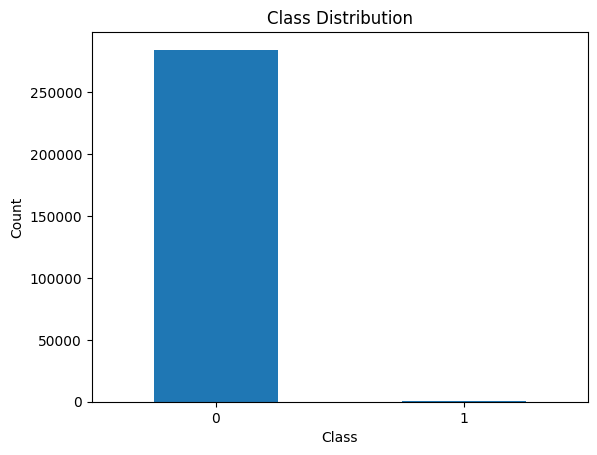

In [3]:
from matplotlib import pyplot as plt

class_count = df['Class'].value_counts()
class_count.plot(kind='bar')
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    stratify=y,
                                                    random_state=42)
print("Number of instances in training set:")
print(y_train.value_counts())
print("\nNumber of instances in test set:")
print(y_test.value_counts())

Number of instances in training set:
Class
0    227451
1       394
Name: count, dtype: int64

Number of instances in test set:
Class
0    56864
1       98
Name: count, dtype: int64


In [5]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy='most_frequent')
dummy_clf.fit(X_train, y_train)
dummy_pred = dummy_clf.predict(X_test)
print(f"Accuracy of dummy classifier: {dummy_clf.score(X_test, y_test)}")

Accuracy of dummy classifier: 0.9982795547909132


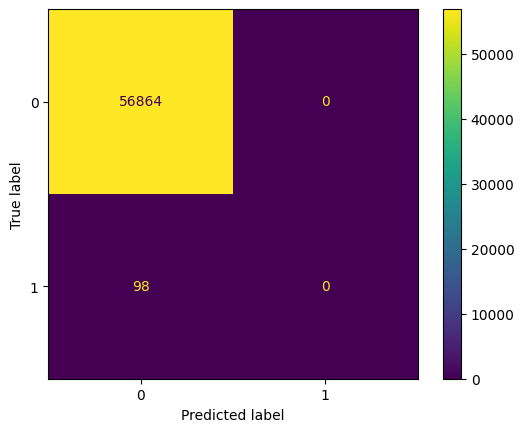

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, dummy_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dummy_clf.classes_)
disp.plot()
plt.show()

In [7]:
from sklearn.naive_bayes import GaussianNB

nb_clf = GaussianNB()
nb_clf.fit(X_train, y_train)
nb_pred = nb_clf.predict(X_test)
print(f"Accuracy of Naive Bayes classifier: {nb_clf.score(X_test, y_test)}")

Accuracy of Naive Bayes classifier: 0.9922755521224677


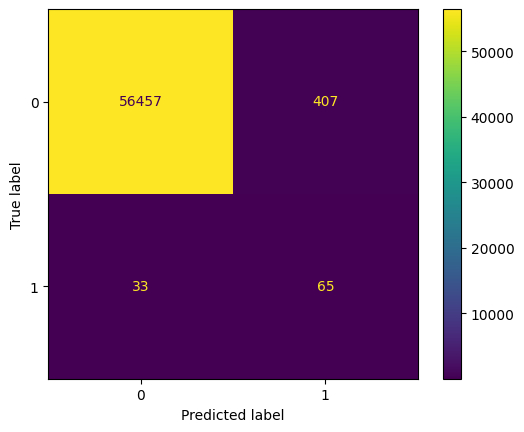

In [8]:
cm = confusion_matrix(y_test, nb_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nb_clf.classes_)
disp.plot()
plt.show()

In [9]:
from sklearn.metrics import classification_report

print(classification_report(y_test, nb_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.14      0.66      0.23        98

    accuracy                           0.99     56962
   macro avg       0.57      0.83      0.61     56962
weighted avg       1.00      0.99      0.99     56962



In [10]:
np_proba = nb_clf.predict_proba(X_test)
np_proba

array([[1.00000000e+00, 1.30855763e-13],
       [1.00000000e+00, 8.45865377e-12],
       [9.99999934e-01, 6.58621565e-08],
       ...,
       [1.00000000e+00, 5.56966487e-14],
       [1.00000000e+00, 8.28200655e-14],
       [1.00000000e+00, 7.20076369e-13]], shape=(56962, 2))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.13      0.68      0.22        98

    accuracy                           0.99     56962
   macro avg       0.57      0.84      0.61     56962
weighted avg       1.00      0.99      0.99     56962



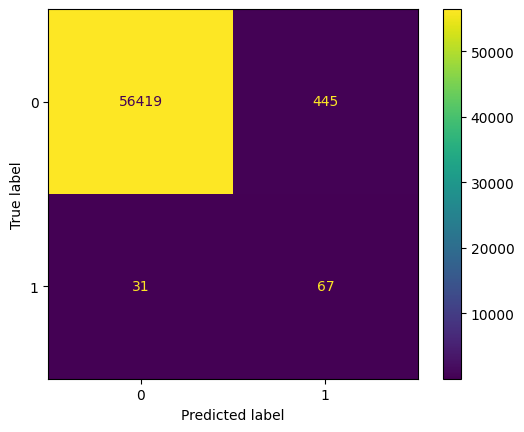

In [11]:
y_prob = np_proba[:, 1]
threshold = 0.2
y_pred = (y_prob >= threshold).astype(int)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_prob >= threshold)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nb_clf.classes_)
disp.plot()
plt.show()

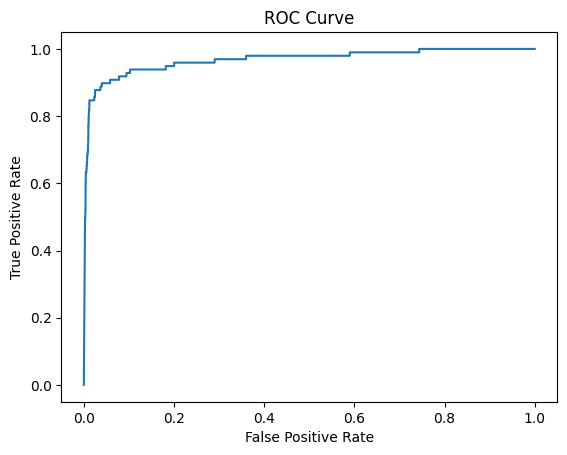

In [12]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

In [13]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_test, y_prob)

np.float64(0.967730650574805)

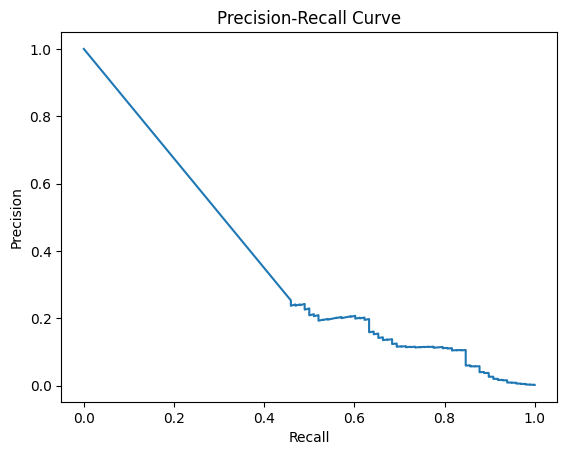

In [14]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.show()

In [15]:
from sklearn.metrics import auc

print(auc(recall, precision))

0.3534873073448916


In [16]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)
X_resampled, y_resampled = ros.fit_resample(X, y)
print("Number of instances per class after oversampling:")
print(pd.Series(y_resampled).value_counts())

Number of instances per class after oversampling:
Class
0    284315
1    284315
Name: count, dtype: int64


              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.12      0.76      0.21        98

    accuracy                           0.99     56962
   macro avg       0.56      0.87      0.60     56962
weighted avg       1.00      0.99      0.99     56962



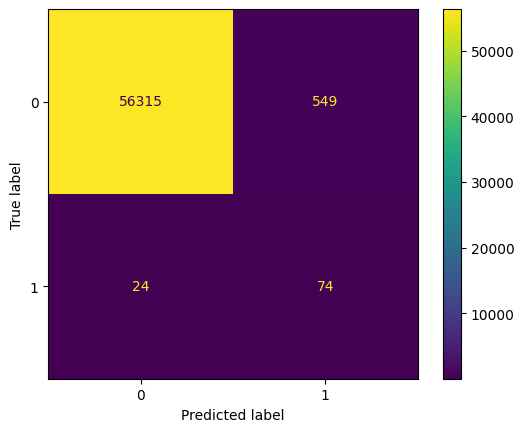

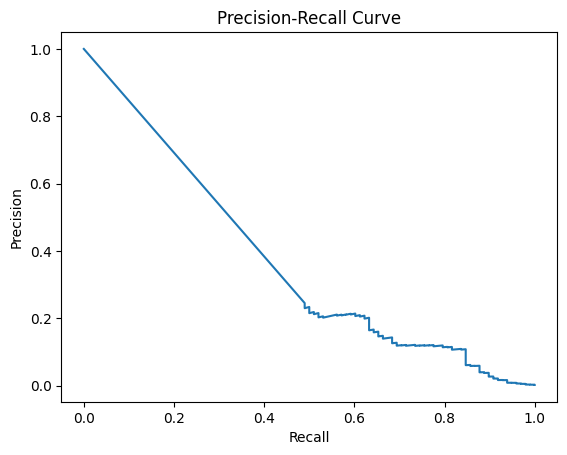

0.3653334702744224


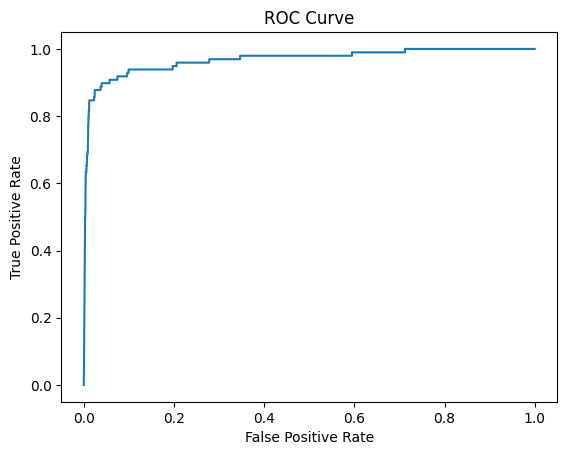

0.9682104024783802


In [17]:
def perform_classification(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot()
    plt.show()
    y_prob = model.predict_proba(X_test)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
    plt.plot(recall, precision)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.show()
    print(auc(recall, precision))
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.show()
    print(roc_auc_score(y_test, y_prob))

perform_classification(GaussianNB(), X_resampled, y_resampled, X_test, y_test)

Number of instances per class after undersampling:
Class
0    492
1    492
Name: count, dtype: int64
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.08      0.74      0.15        98

    accuracy                           0.99     56962
   macro avg       0.54      0.87      0.57     56962
weighted avg       1.00      0.99      0.99     56962



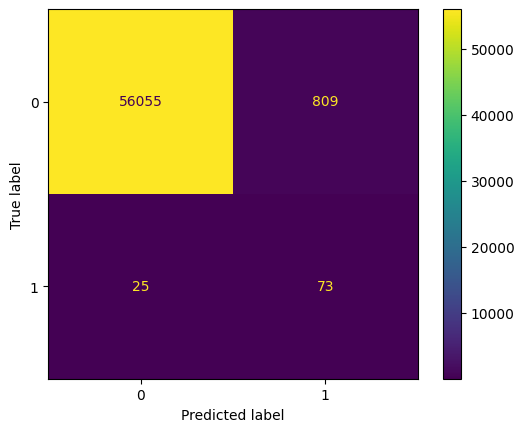

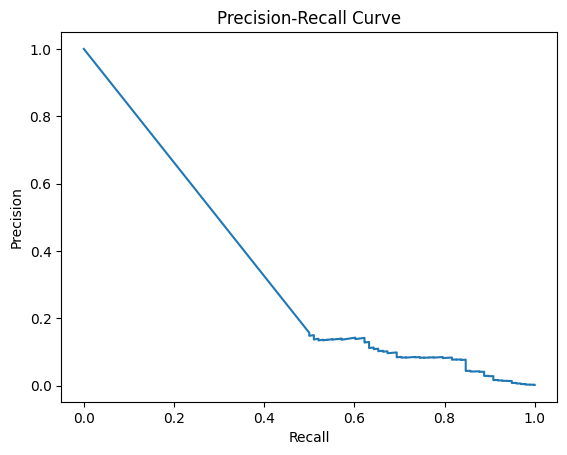

0.32943137544438955


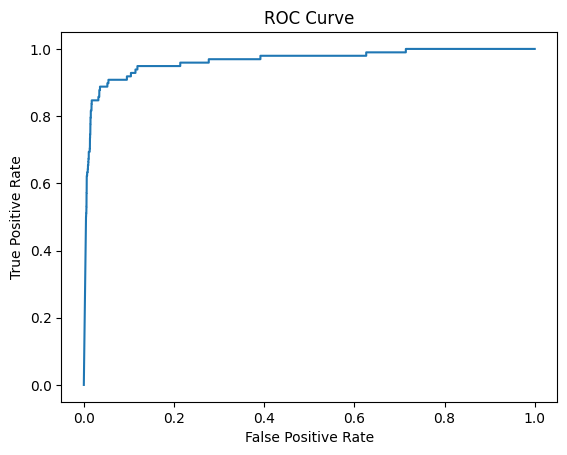

0.9655457023130017


In [18]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_resampled, y_resampled = rus.fit_resample(X, y)
print("Number of instances per class after undersampling:")
print(pd.Series(y_resampled).value_counts())

perform_classification(GaussianNB(), X_resampled, y_resampled, X_test, y_test)

Number of instances per class after SMOTE:
Class
0    284315
1    284315
Name: count, dtype: int64
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.15      0.79      0.25        98

    accuracy                           0.99     56962
   macro avg       0.57      0.89      0.62     56962
weighted avg       1.00      0.99      0.99     56962



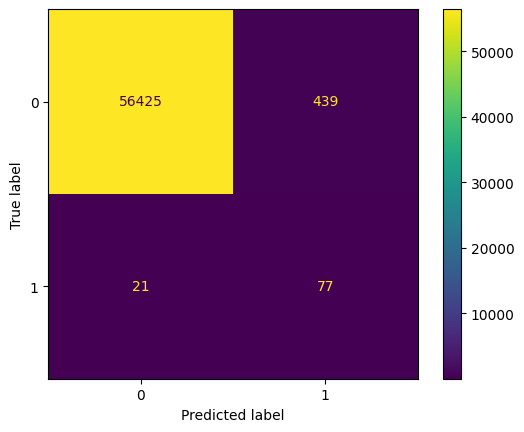

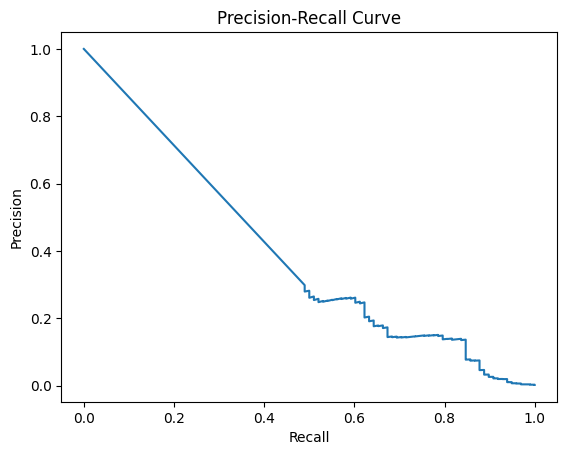

0.39053938018863954


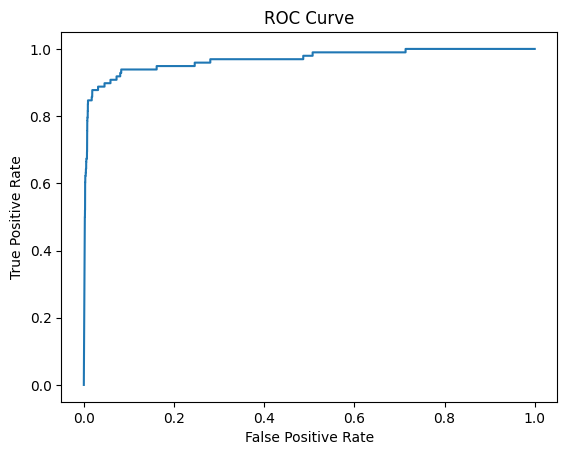

0.9687213781826742


In [19]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)
print("Number of instances per class after SMOTE:")
print(pd.Series(y_resampled).value_counts())

perform_classification(GaussianNB(), X_resampled, y_resampled, X_test, y_test)

In [20]:
# from imblearn.under_sampling import EditedNearestNeighbours

# enn = EditedNearestNeighbours()
# X_resampled, y_resampled = enn.fit_resample(X, y)
# print("Number of instances per class after undersampling:")
# print(pd.Series(y_resampled).value_counts())

# perform_classification(GaussianNB(), X_resampled, y_resampled, X_test, y_test)

In [21]:
# from imblearn.combine import SMOTEENN

# smoteenn = SMOTEENN(random_state=42)
# X_resampled, y_resampled = smoteenn.fit_resample(X, y)
# print("Number of instances per class after SMOTEENN:")
# print(pd.Series(y_resampled).value_counts())

# perform_classification(GaussianNB(), X_resampled, y_resampled, X_test, y_test)

In [23]:
from imblearn.pipeline import Pipeline

pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('model', GaussianNB())
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.15      0.80      0.25        98

    accuracy                           0.99     56962
   macro avg       0.57      0.89      0.62     56962
weighted avg       1.00      0.99      0.99     56962



              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.15      0.80      0.25        98

    accuracy                           0.99     56962
   macro avg       0.57      0.89      0.62     56962
weighted avg       1.00      0.99      0.99     56962



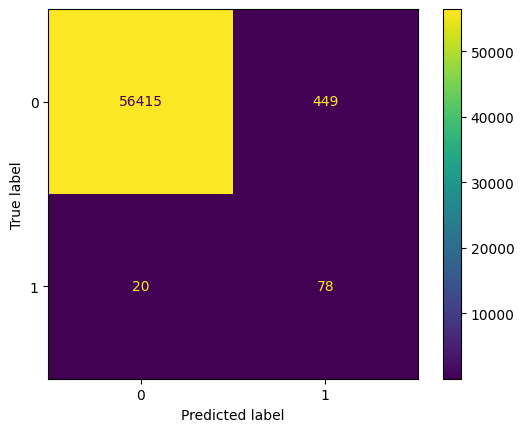

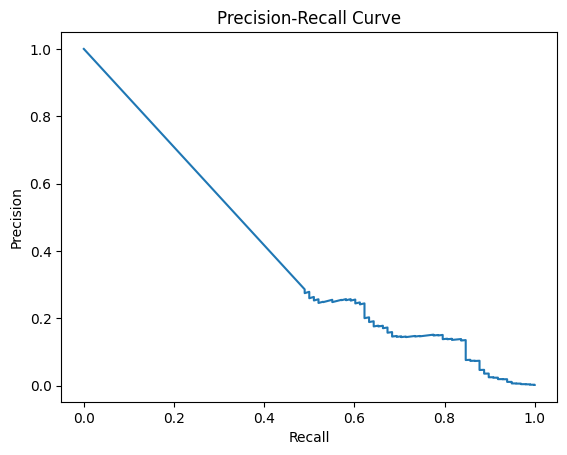

0.3872381328181127


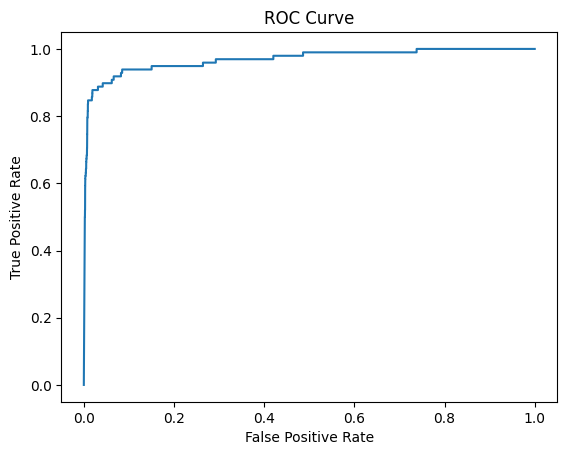

0.969172239098228


In [24]:
from imblearn.pipeline import make_pipeline

smote_nb = make_pipeline(SMOTE(random_state=42), GaussianNB())
perform_classification(smote_nb, X_train, y_train, X_test, y_test)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# rf_clf = RandomForestClassifier(random_state=42)
# perform_classification(rf_clf, X_train, y_train, X_test, y_test)

              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56864
           1       0.04      0.92      0.08        98

    accuracy                           0.96     56962
   macro avg       0.52      0.94      0.53     56962
weighted avg       1.00      0.96      0.98     56962



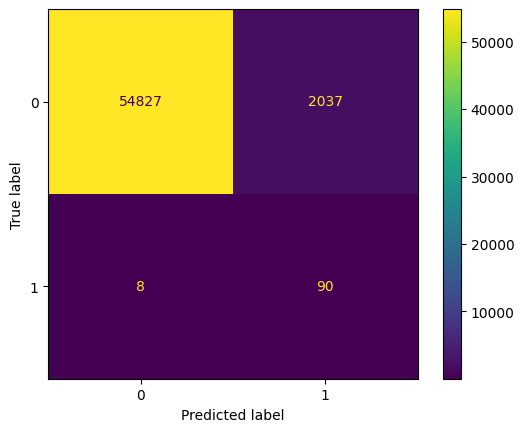

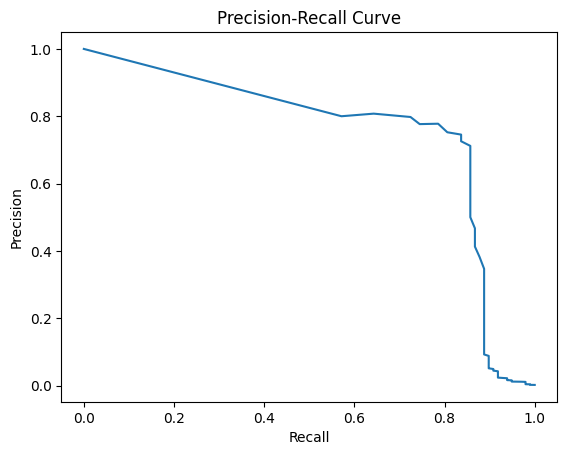

0.753825993338084


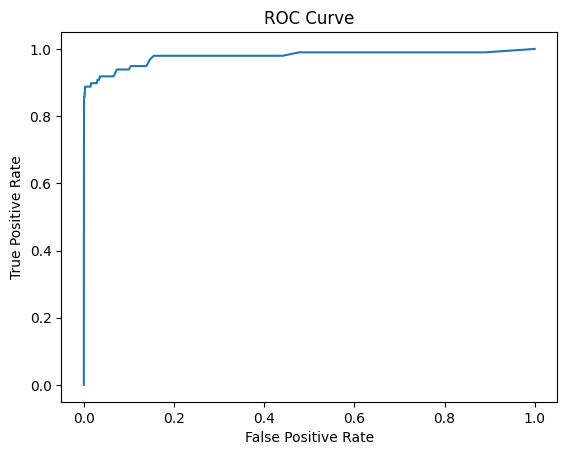

0.9776978619951074


In [27]:
rus_rf = make_pipeline(RandomUnderSampler(random_state=42), RandomForestClassifier(random_state=42))
perform_classification(rus_rf, X_train, y_train, X_test, y_test)

In [ ]:
# smote_rf = make_pipeline(SMOTE(random_state=42), RandomForestClassifier(random_state=42))
# perform_classification(smote_rf, X_train, y_train, X_test, y_test)

In [ ]:
# ros_rf = make_pipeline(RandomOverSampler(random_state=42), RandomForestClassifier(random_state=42))
# perform_classification(ros_rf, X_train, y_train, X_test, y_test)

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.12      0.89      0.22        98

    accuracy                           0.99     56962
   macro avg       0.56      0.94      0.61     56962
weighted avg       1.00      0.99      0.99     56962



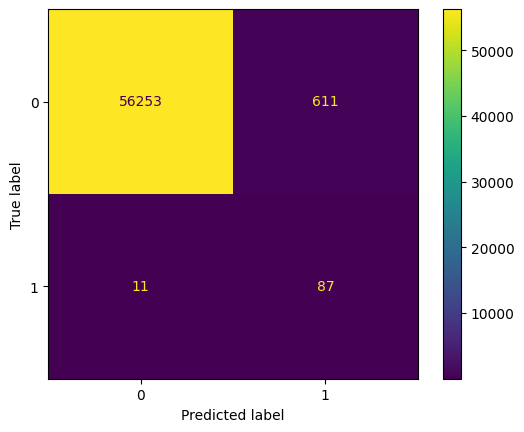

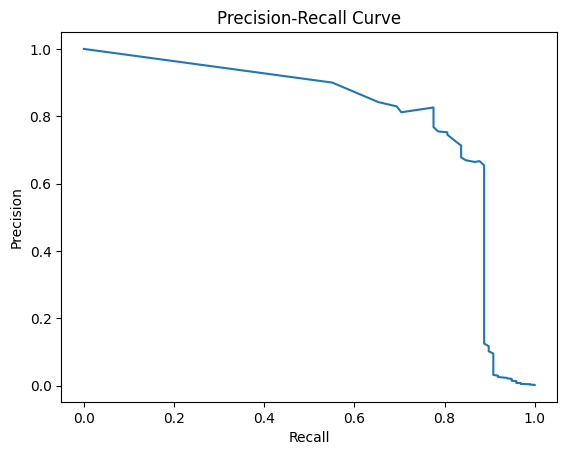

0.7963616428040732


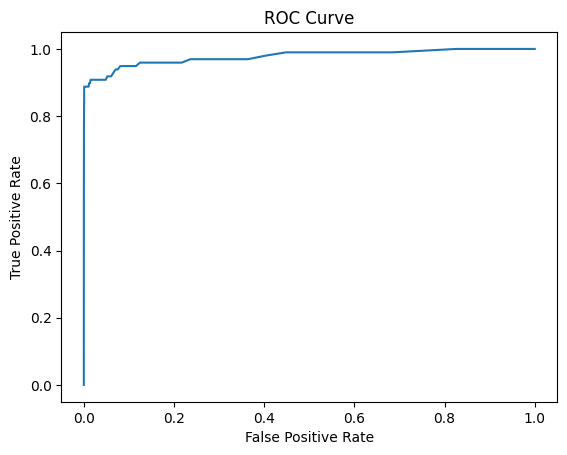

0.9774662854731088


In [29]:
from imblearn.ensemble import BalancedRandomForestClassifier

brf_clf = BalancedRandomForestClassifier(random_state=42)
perform_classification(brf_clf, X_train, y_train, X_test, y_test)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.59      0.82      0.68        98

    accuracy                           1.00     56962
   macro avg       0.79      0.91      0.84     56962
weighted avg       1.00      1.00      1.00     56962



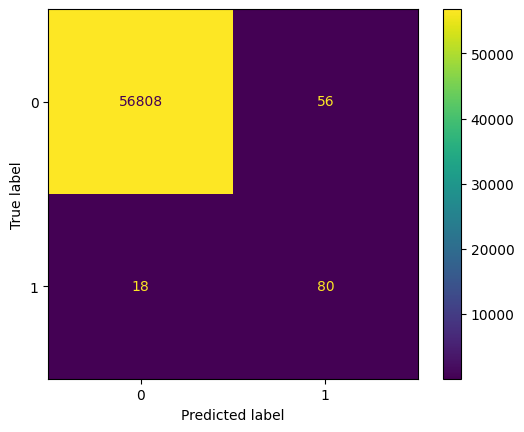

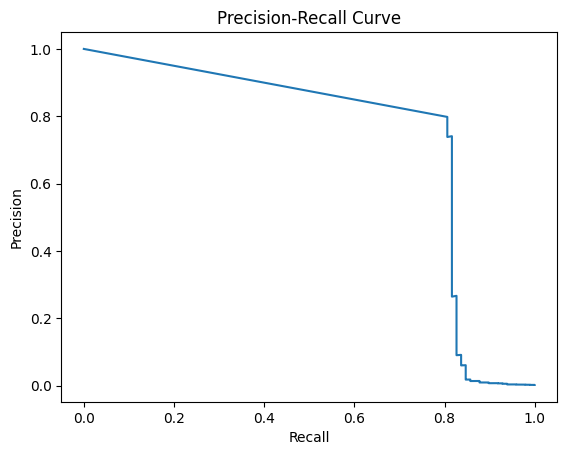

0.7375381610472888


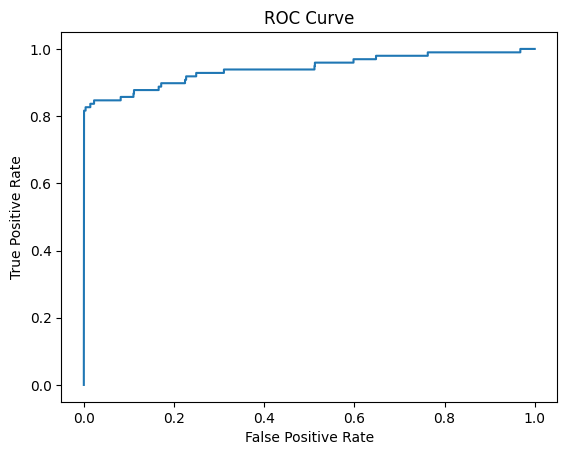

0.9417512819703008


In [31]:
from sklearn.neural_network import MLPClassifier

mlp_clf = MLPClassifier(random_state=42)
perform_classification(mlp_clf, X_train, y_train, X_test, y_test)

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.04      0.26      0.07        98

    accuracy                           0.99     56962
   macro avg       0.52      0.62      0.53     56962
weighted avg       1.00      0.99      0.99     56962



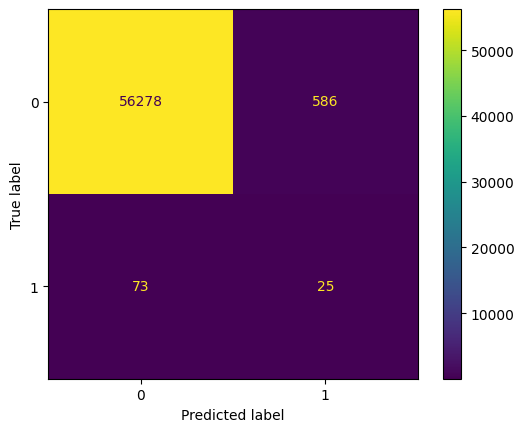

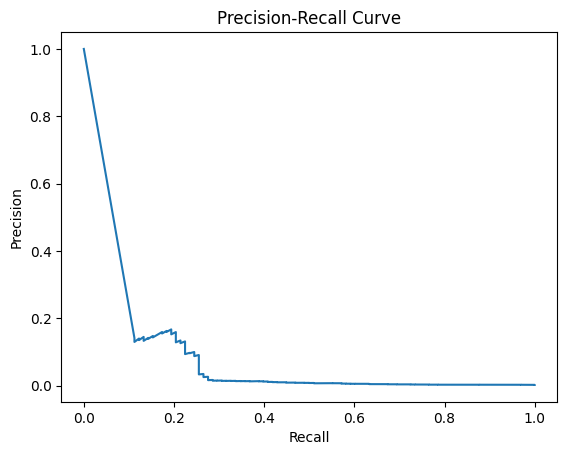

0.08817628694291195


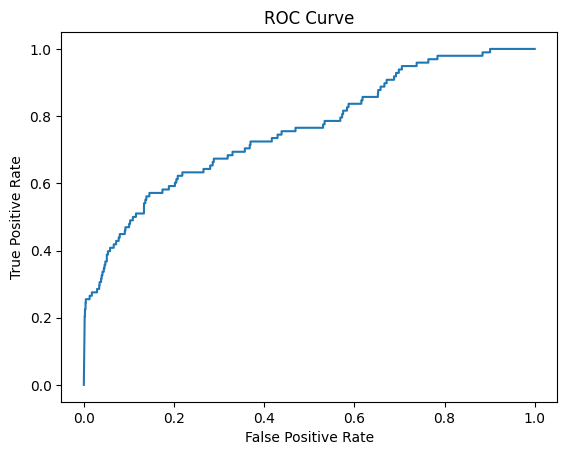

0.7599838102798802


In [32]:
rus_mlp = make_pipeline(RandomUnderSampler(random_state=42), MLPClassifier(random_state=42))
perform_classification(rus_mlp, X_train, y_train, X_test, y_test)

              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.88      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.92      0.54     56962
weighted avg       1.00      0.97      0.98     56962



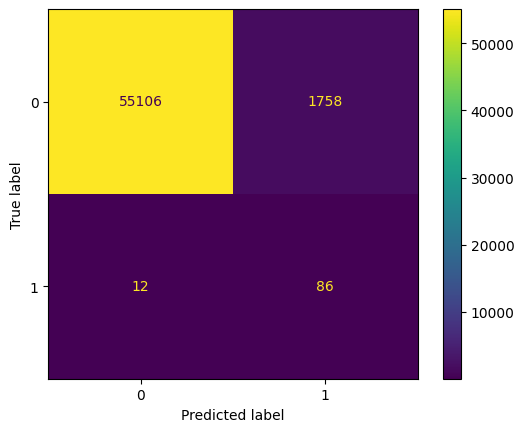

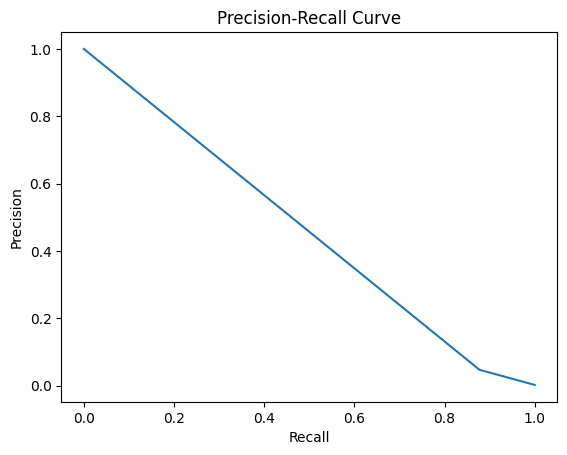

0.4621997156015834


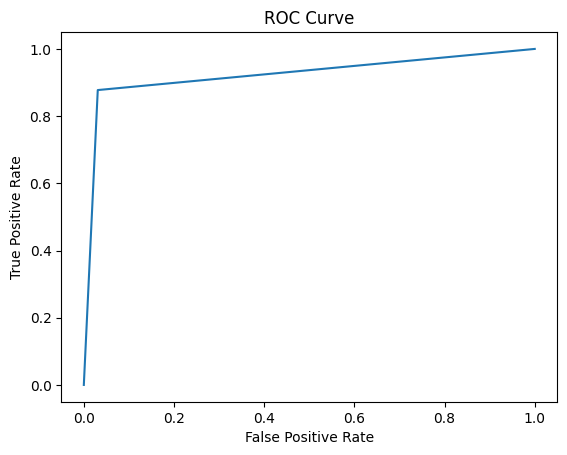

0.9233175754826409


In [34]:
from imblearn.ensemble import RUSBoostClassifier

rusboost_clf = RUSBoostClassifier(random_state=42)
perform_classification(rusboost_clf, X_train, y_train, X_test, y_test)

In [39]:
from imblearn.under_sampling import NearMiss

nm = NearMiss(version=3)
X_resampled, y_resampled = nm.fit_resample(X, y)
print("Number of instances per class after NearMiss:")
print(pd.Series(y_resampled).value_counts())

Number of instances per class after NearMiss:
Class
0    492
1    492
Name: count, dtype: int64


              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.13      0.73      0.23        98

    accuracy                           0.99     56962
   macro avg       0.57      0.86      0.61     56962
weighted avg       1.00      0.99      0.99     56962



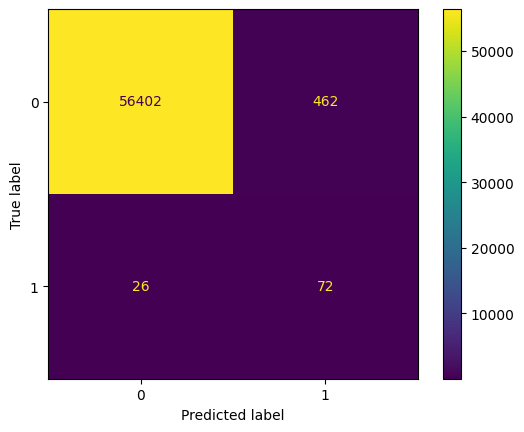

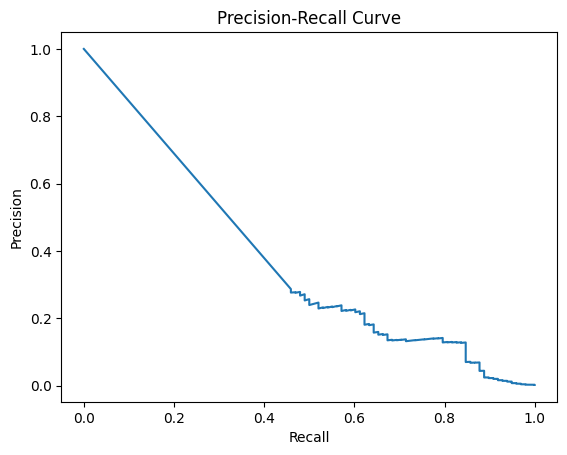

0.3699876003128582


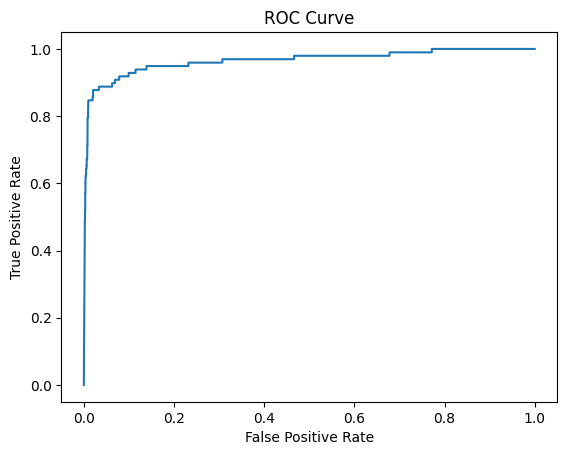

0.9655334999081231


In [40]:
nm_nb = make_pipeline(NearMiss(version=3), GaussianNB())
perform_classification(nm_nb, X_train, y_train, X_test, y_test)

              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.91      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.94      0.54     56962
weighted avg       1.00      0.97      0.98     56962



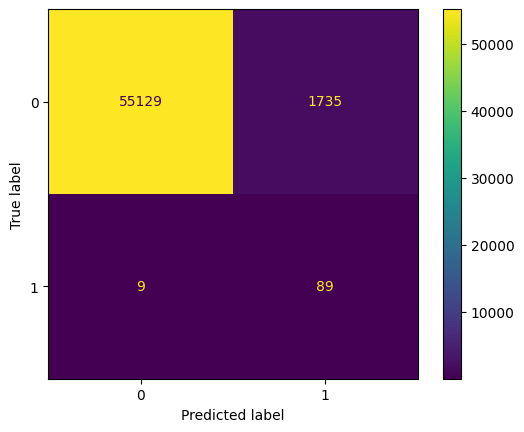

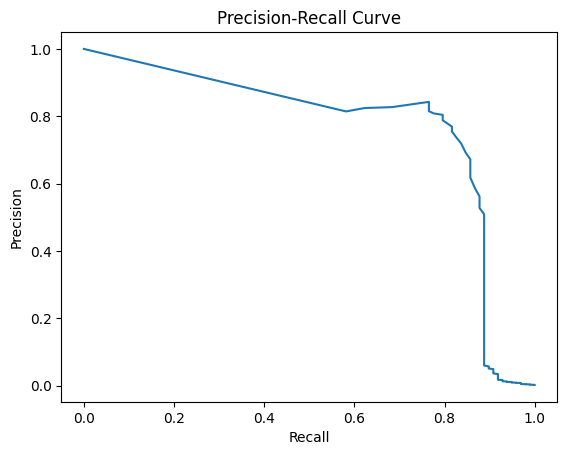

0.7690067063912296


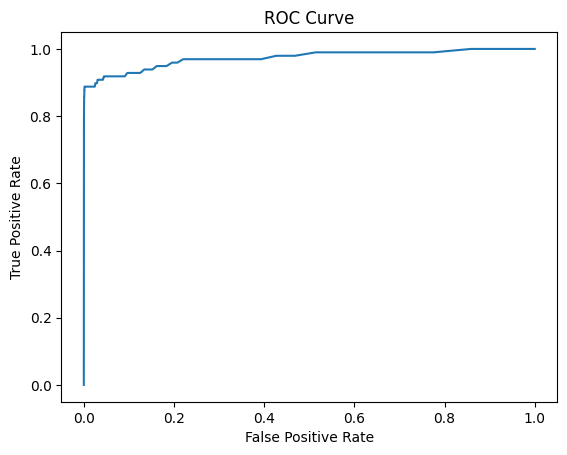

0.9732807708761614


In [41]:
nm_rf = make_pipeline(NearMiss(version=3), RandomForestClassifier(random_state=42))
perform_classification(nm_rf, X_train, y_train, X_test, y_test)

              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56864
           1       0.04      0.92      0.08        98

    accuracy                           0.96     56962
   macro avg       0.52      0.94      0.53     56962
weighted avg       1.00      0.96      0.98     56962



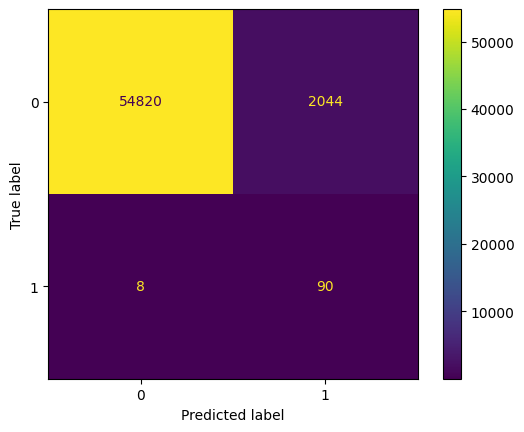

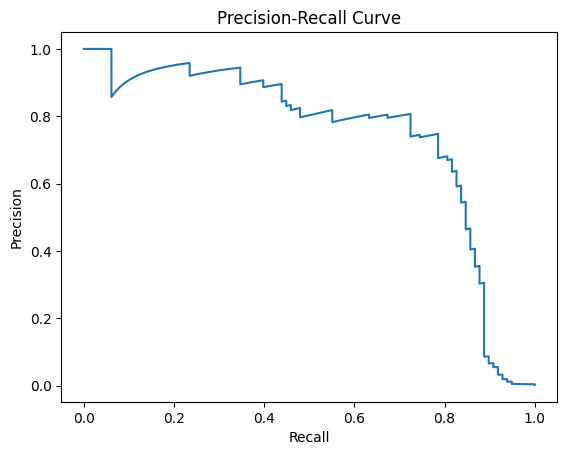

0.7419795854645844


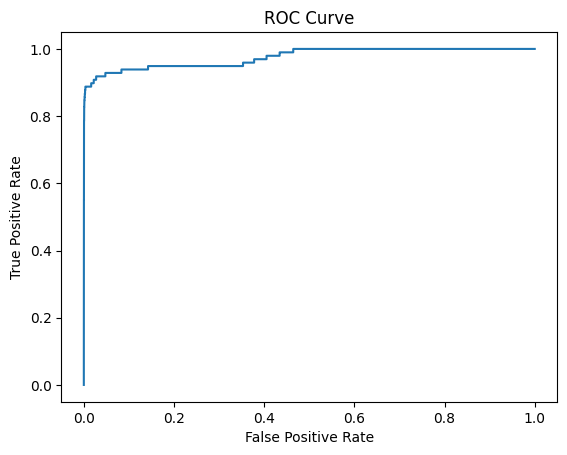

0.9755104911970416


In [43]:
from imblearn.ensemble import EasyEnsembleClassifier

ee_clf = EasyEnsembleClassifier(random_state=42)
perform_classification(ee_clf, X_train, y_train, X_test, y_test)

In [ ]:
from imblearn.under_sampling import EditedNearestNeighbours

enn = EditedNearestNeighbours()
X_resampled, y_resampled = enn.fit_resample(X, y)
print("Number of instances per class after EditedNearestNeighbours:")
print(pd.Series(y_resampled).value_counts())

In [ ]:
perform_classification(GaussianNB(), X_resampled, y_resampled, X_test, y_test)

In [ ]:
perform_classification(RandomForestClassifier(random_state=42), X_resampled, y_resampled, X_test, y_test)

In [ ]:
perform_classification(MLPClassifier(random_state=42), X_resampled, y_resampled, X_test, y_test)